# Current-main 64-source batch timing

Keep the same **64 distinct sources** and detector block, and vary the JAX
source chunk size from 1 to 64. Geometry and TDI operators are precomputed,
and each array shape is warmed before its three measured repetitions.

Two outputs are measured separately:

- **Independent XYZ:** retain 64 separate source responses. The timing helper
  composes `jax.vmap` with the current package's existing single-source link
  kernel, then applies the prepared PyTDI operator to each source. This is a
  batching experiment; the public `eccentric_links_jax` API itself sums sources.
- **Summed XYZ:** use the current public batch API for the combined response
  of the same 64 sources, followed by one prepared TDI evaluation.

Each chunk size runs in an isolated subprocess so peak RSS is attributable
to that worker. The default block has 65,536 retained samples at 5 s cadence,
or about 3.79 days, with 128 padding samples on either side. These are block
throughput measurements, rather than full-year fitting-factor timings.

Use Python 3.12+ with `pip install -e ".[orbits,notebook]"`. Restart the kernel
and run all cells. No waveform files are saved.

In [1]:
from pathlib import Path
from dataclasses import replace
from time import perf_counter
import hashlib
import importlib.metadata as metadata
import inspect
import json
import os
import platform
import subprocess
import sys

# Load the current checkout, whether launched from its root or notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/egb_jax_eccentric").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or notebooks/ directory")
sys.path.insert(0, str(ROOT / "src"))
os.environ["JAX_PLATFORMS"] = "cpu"
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)

from egb_jax_eccentric import (
    EccentricBinaryParams, LINK_LABELS, default_lisaorbits,
    state_from_lisaorbits, precompute_jax_link_geometry,
    eccentric_links_jax, prepare_xyz_from_links, xyz_from_links,
)
assert Path(inspect.getfile(prepare_xyz_from_links)).is_relative_to(ROOT), (
    "Restart the kernel to load this checkout")

environment = {
    "python": platform.python_version(), "platform": platform.platform(),
    "devices": [str(device) for device in jax.devices()],
    "jax_float64": jax.config.x64_enabled,
    "versions": {name: metadata.version(name) for name in
                 ("numpy", "scipy", "jax", "jaxlib", "pytdi", "lisaorbits")},
    "tdi_source_sha256": hashlib.sha256(
        Path(inspect.getfile(prepare_xyz_from_links)).read_bytes()).hexdigest(),
}
print(json.dumps(environment, indent=2))


{
  "python": "3.12.13",
  "platform": "macOS-27.0.1-arm64-arm-64bit",
  "devices": [
    "cpu:0"
  ],
  "jax_float64": true,
  "versions": {
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "jax": "0.11.2",
    "jaxlib": "0.11.2",
    "pytdi": "2.2.1",
    "lisaorbits": "3.1.0"
  },
  "tdi_source_sha256": "0c5486112037ee219de879e510d34102f663b2c300a02e5a6425b1c9b7166ae4"
}


In [2]:
source_count = 64
block_samples = 65536
repeats = 3
batch_sizes = [1, 4, 8, 16, 32, 64]
worker = ROOT / "benchmarks/prepared_xyz_batch_timing.py"
assert worker.is_file()
assert all(source_count % size == 0 for size in batch_sizes)

rows = []
for size in batch_sizes:
    print(f"Testing chunk size {size}: 64 separate waveforms and the summed response", flush=True)
    command = [sys.executable, str(worker), "--batch-size", str(size),
        "--sources", str(source_count), "--block-samples", str(block_samples),
        "--repeats", str(repeats)]
    process = subprocess.run(command, cwd=ROOT, capture_output=True, text=True)
    if process.returncode:
        raise RuntimeError(f"Batch {size} failed:\n{process.stderr}")
    row = json.loads(process.stdout)
    rows.append(row)
    print(f"  Independent: {row['independent_warm_median_s']:.3f} s; "
          f"summed: {row['summed_warm_median_s']:.3f} s; "
          f"worker peak RSS: {row['process_peak_rss_mib']:.1f} MiB", flush=True)

assert len({row["source_parameter_sha256"] for row in rows}) == 1
assert len({row["geometry_sha256"] for row in rows}) == 1
assert all(row["maximum_independent_normalized_vector_change_bound"] <= row["normalized_overlap_bound_allowance"] for row in rows)
assert all(row["summed_normalized_vector_change_bound"] <= row["normalized_overlap_bound_allowance"] for row in rows)
print("All chunk sizes used identical sources/geometry and passed scalar/superposition checks.")

Testing chunk size 1: 64 separate waveforms and the summed response


  Independent: 2.419 s; summed: 1.016 s; worker peak RSS: 1020.1 MiB


Testing chunk size 4: 64 separate waveforms and the summed response


  Independent: 2.273 s; summed: 1.194 s; worker peak RSS: 1255.2 MiB


Testing chunk size 8: 64 separate waveforms and the summed response


...

Testing chunk size 32: 64 separate waveforms and the summed response


  Independent: 2.720 s; summed: 1.969 s; worker peak RSS: 3427.5 MiB


Testing chunk size 64: 64 separate waveforms and the summed response


  Independent: 3.020 s; summed: 2.642 s; worker peak RSS: 6087.6 MiB


All chunk sizes used identical sources/geometry and passed scalar/superposition checks.


| JAX chunk | 64 independent XYZ | Time/source | Independent speedup | Summed XYZ | Peak RSS |
|---:|---:|---:|---:|---:|---:|
| 1 | 2.419 s | 37.80 ms | 1.00× | 1.016 s | 1020 MiB |
| 4 | 2.273 s | 35.51 ms | 1.06× | 1.194 s | 1255 MiB |
| 8 | 2.246 s | 35.10 ms | 1.08× | 1.259 s | 1430 MiB |
| 16 | 2.529 s | 39.51 ms | 0.96× | 1.663 s | 2138 MiB |
| 32 | 2.720 s | 42.49 ms | 0.89× | 1.969 s | 3427 MiB |
| 64 | 3.020 s | 47.19 ms | 0.80× | 2.642 s | 6088 MiB |

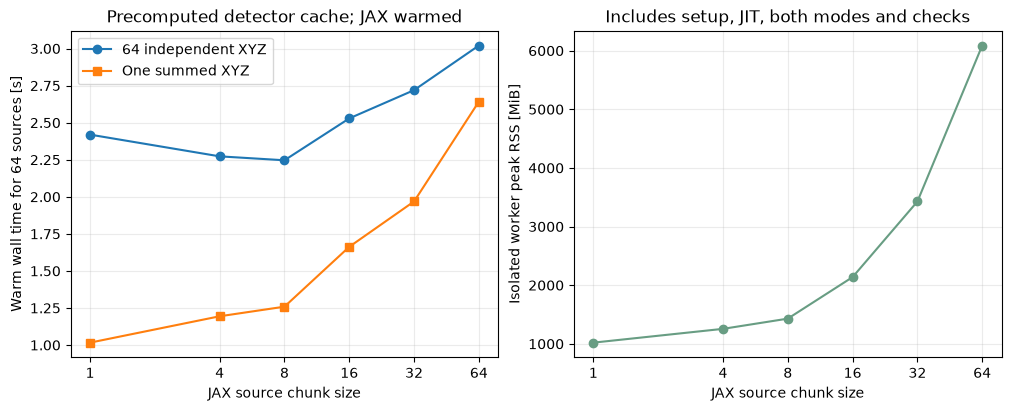

Fastest tested independent chunk size: 8
This is an observed block-throughput result, not a maximum supported batch size.


In [3]:
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

serial = rows[0]["independent_warm_median_s"]
table = ["| JAX chunk | 64 independent XYZ | Time/source | Independent speedup | Summed XYZ | Peak RSS |",
    "|---:|---:|---:|---:|---:|---:|"]
for row in rows:
    seconds = row["independent_warm_median_s"]
    table.append(f"| {row['batch_size']} | {seconds:.3f} s | "
        f"{1000 * seconds / source_count:.2f} ms | {serial / seconds:.2f}× | "
        f"{row['summed_warm_median_s']:.3f} s | {row['process_peak_rss_mib']:.0f} MiB |")
display(Markdown("\n".join(table)))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
sizes = np.array(batch_sizes)
axes[0].plot(sizes, [r["independent_warm_median_s"] for r in rows], "o-", label="64 independent XYZ")
axes[0].plot(sizes, [r["summed_warm_median_s"] for r in rows], "s-", label="One summed XYZ")
axes[0].set_ylabel("Warm wall time for 64 sources [s]")
axes[0].set_title("Precomputed detector cache; JAX warmed")
axes[0].legend()
axes[1].plot(sizes, [r["process_peak_rss_mib"] for r in rows], "o-", color="#689D83")
axes[1].set_ylabel("Isolated worker peak RSS [MiB]")
axes[1].set_title("Includes setup, JIT, both modes and checks")
for axis in axes:
    axis.set_xscale("log", base=2)
    axis.set_xticks(sizes, [str(n) for n in sizes])
    axis.set_xlabel("JAX source chunk size")
    axis.grid(alpha=.25)
plt.show()

best = min(rows, key=lambda r: r["independent_warm_median_s"])
print(f"Fastest tested independent chunk size: {best['batch_size']}")
print("This is an observed block-throughput result, not a maximum supported batch size.")

In [4]:
# Cold/setup measurements remain separate from the warmed comparison.
cold = ["| Chunk | Geometry setup | TDI setup | Independent first pass | Summed first pass |",
        "|---:|---:|---:|---:|---:|"]
for row in rows:
    cold.append(f"| {row['batch_size']} | {row['geometry_setup_s']:.3f} s | "
        f"{row['tdi_setup_s']:.3f} s | {row['independent_first_pass_s']:.3f} s | "
        f"{row['summed_first_pass_s']:.3f} s |")
display(Markdown("\n".join(cold)))
print(f"Independent output shape: {rows[-1]['independent_output_shape']}")
print(f"Summed output shape: {rows[-1]['summed_output_shape']}")
print(f"Largest independent/scalar relative error: {max(r['maximum_independent_scalar_relative_error'] for r in rows):.3e}")
print(f"Largest superposition relative error: {max(r['summed_vs_independent_relative_error'] for r in rows):.3e}")
print(f"Largest unweighted normalized-vector change bound: {max(max(r['maximum_independent_normalized_vector_change_bound'], r['summed_normalized_vector_change_bound']) for r in rows):.3e}")
print("Tight 2e-12 relative screens:", {r["batch_size"]: r["strict_2e12_relative_screen_passed"] for r in rows})

| Chunk | Geometry setup | TDI setup | Independent first pass | Summed first pass |
|---:|---:|---:|---:|---:|
| 1 | 0.629 s | 0.053 s | 2.580 s | 1.022 s |
| 4 | 0.559 s | 0.053 s | 2.430 s | 1.364 s |
| 8 | 0.565 s | 0.053 s | 2.459 s | 1.475 s |
| 16 | 0.576 s | 0.054 s | 2.745 s | 1.893 s |
| 32 | 0.578 s | 0.056 s | 3.258 s | 2.705 s |
| 64 | 0.581 s | 0.057 s | 5.091 s | 7.481 s |

Independent output shape: [64, 3, 65792]
Summed output shape: [3, 65792]
Largest independent/scalar relative error: 6.355e-12
Largest superposition relative error: 2.888e-15
Largest unweighted normalized-vector change bound: 1.271e-11
Tight 2e-12 relative screens: {1: True, 4: False, 8: False, 16: False, 32: False, 64: False}


All cases use CPU float64, fixed 1PN evolution with periastron advance,
native retarded ESA-trailing geometry in ecliptic J2000, and frequency-unit
generation-2 TDI at orders 3/3. The same delay arrays feed links and TDI.

Warm timings include fresh link generation, synchronization/host materialization,
and TDI evaluation; they exclude geometry/operator preparation, first-pass
compilation, validation and process startup. Independent source parameters
are packed once before timing; the public summed API performs its usual packing.
Chunk comparisons within each output mode use the same workload. The two
output modes perform different tasks and their times are not interchangeable.

Each independent source is checked against the public scalar API. The sum of
independent XYZ is checked against the public summed-catalogue response, using
TDI linearity. Peak RSS is the worker's lifetime high-water mark, including
both kernels, compilation and these checks; it is not the memory of the
waveform output alone. No maximum batch size beyond 64 or full-year throughput
is inferred. Cadence convergence and the optimized fitting-factor search are
separate calculations.

The agreement gate requires the conservative unweighted normalized-vector
change bound `2*epsilon/(1-epsilon)` to stay below `1e-8`, where epsilon is
relative XYZ L2 error against the scalar/superposition reference. JAX batch
shapes can change floating-point evaluation order. The tighter `2e-12`
relative-error screen is retained and reported separately, along with all
measured discrepancies. This is an unweighted consistency check, not a
noise-weighted fitting-factor accuracy certificate.

CPU workers inherit the current machine or Slurm allocation and thread settings;
this notebook imposes no additional CPU-affinity cap. The committed example
outputs were measured on the Mac CPU, rather than the one-CPU Euler pilot allocation.
